In [26]:
import numpy as np
from scipy import io
import matplotlib.pyplot as plt
from src.utils import setup_plot_style
from LinearExperiment import LinearAnalysis
from ActivityPipelines import ActivityLoader
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os

colors = setup_plot_style()

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'
session = r'250225_SAM032'

session_path = os.path.join(data_dir, session)
stimulus_path = os.path.join(session_path, r'stimulus')
activity_path = os.path.join(session_path, r'suite2p\plane0')

# check files inside stimulus_path
filelist = [file for file in os.listdir(stimulus_path) if file.endswith(("_stimulus.mat"))]
if len(filelist) == 0:
    # raise error
    raise Exception('No stimulus file found')
elif len(filelist) > 1:
    raise Exception('More than one stimulus file found')
else:
    print('Stimulus file found')

container = io.loadmat(stimulus_path + '/' + str(filelist[0]))

D = ActivityLoader(session_path)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Stimulus file found


In [18]:
time = container['stim']['time'][0][0][0]
stepper_pos = container['stim']['stepper_pos'][0][0][0]
servo_id = container['stim']['servo_id'][0][0][0]
mini_servo_active = container['stim']['mini_servo_active'][0][0][0]
trial_sequence = container['stim']['trial_sequence'][0][0][0]
history_sequence = container['stim']['history_sequence'][0][0][0]
trial_start_time = container['stim']['trial_start_time'][0][0][0]
trial_end_time = container['stim']['trial_end_time'][0][0][0]

In [25]:
D.frames_time

array([0.00000000e+00, 9.92683700e+01, 1.98536740e+02, ...,
       1.39174255e+06, 1.39184182e+06, 1.39194108e+06])

In [303]:
# plotting the trace and the size vs time
container = io.loadmat(self.stimulus_path + '/' + str(filelist[0]))

12.528807709151511
14.381394591090604


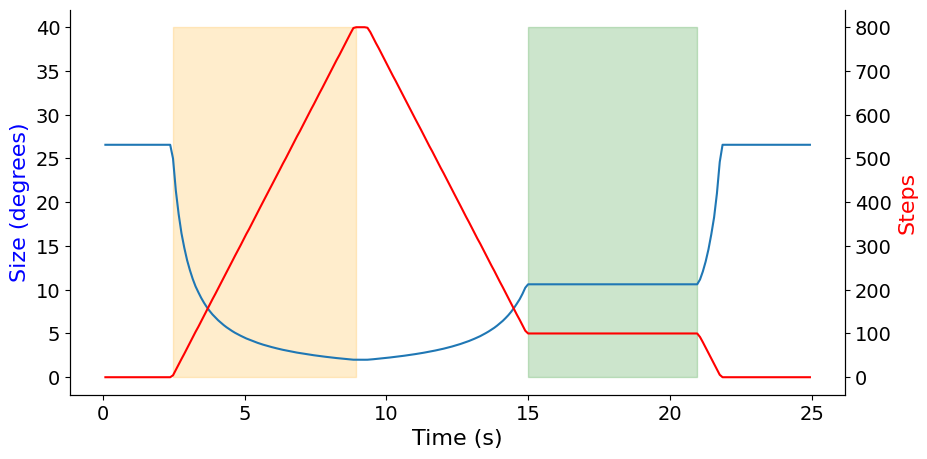

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

repeat_frames = L.get_repeat_frames(0)
repeat_size = L.get_repeat_size(0)

distancing_frames = L.get_distancing_frames_within_repeat(0)
stopped_frames = L.get_stopped_frames_within_repeat(0)

# ax1 will be size with respect to time and distance travelled with respect to time
ax.plot(L.frames_time[repeat_frames]/1000, repeat_size)
ax.set_ylabel('Size (degrees)', color='blue')
ax.set_xlabel('Time (s)')
ax2 = ax.twinx()
ax2.plot(L.frames_time[repeat_frames]/1000, 30*L.distance_traveled[repeat_frames], color='red')
ax2.set_ylabel('Steps', color='red')
# ax2.set_title('Stim size = ' + str(2*L.stim_showed[0]) + ' cm')
# highlight times where it is distancing
ax.fill_between(L.frames_time[repeat_frames][distancing_frames]/1000, 0, 40, color='orange', alpha=0.2)
ax.fill_between(L.frames_time[repeat_frames][stopped_frames]/1000, 0, 40, color='green', alpha=0.2)
# set all right and top splines to be removed
ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

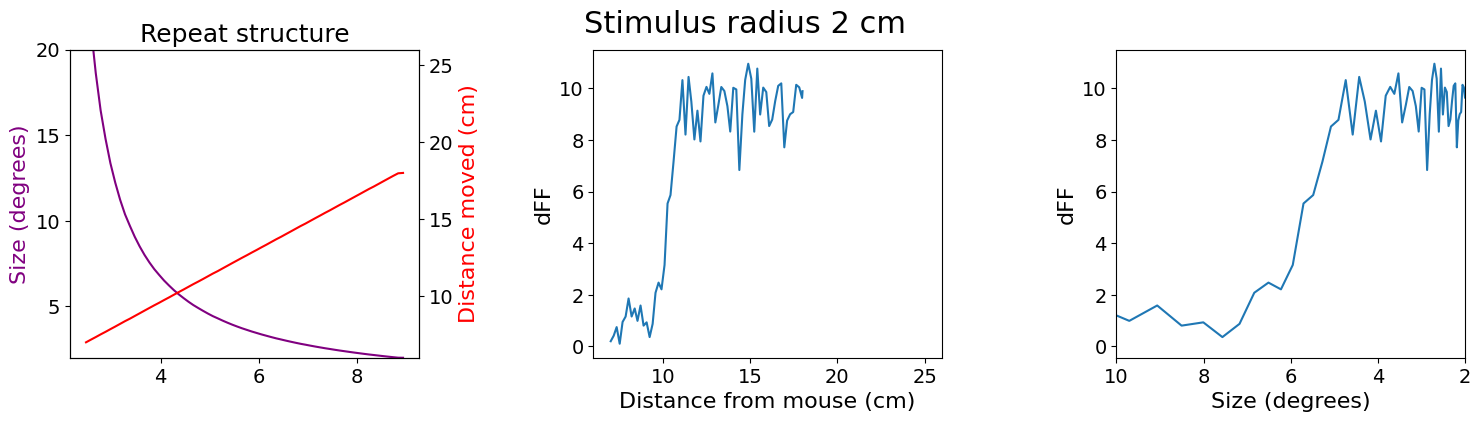

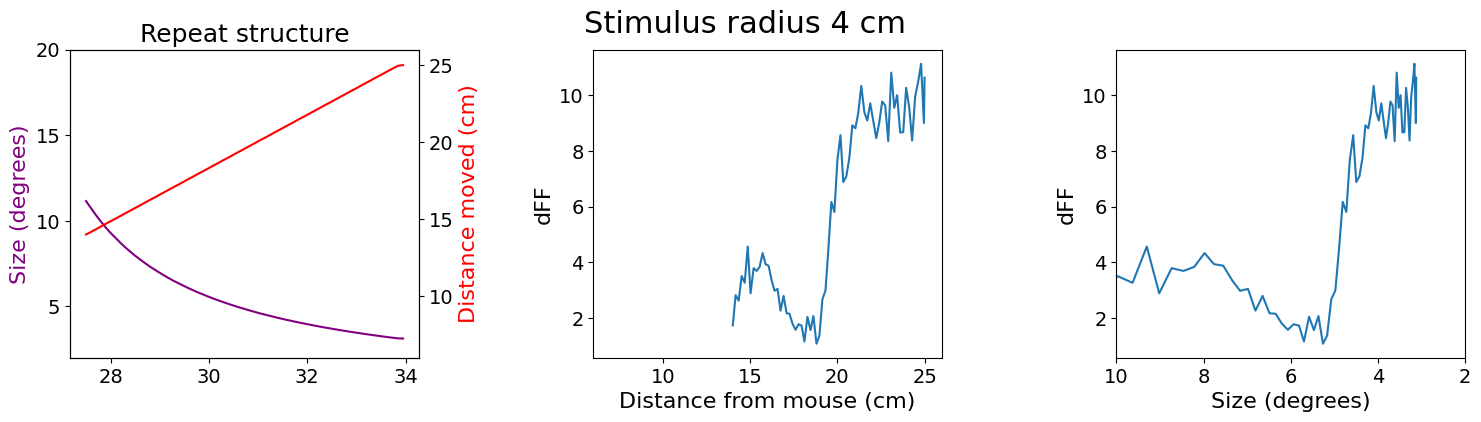

In [14]:
# make figure with 3 subplots
for repeat in range(2):

    cell = 0

    repeat_frames = L.get_repeat_frames(repeat)
    repeat_frames_within_repeat = L.get_distancing_frames_within_repeat(repeat)
    repeat_distancing_times = L.frames_time[repeat_frames][repeat_frames_within_repeat]
    repeat_distancing_trace = L.get_distancing_trace(cell, repeat)
    repeat_distancing_size = L.get_distancing_size(repeat)
    repeat_distancing_distance = L.distance_traveled[repeat_frames][repeat_frames_within_repeat]

    # scale distancing_distance from 0 to 1
    repeat_distancing_distance = (repeat_distancing_distance - np.min(repeat_distancing_distance))/(np.max(repeat_distancing_distance) - np.min(repeat_distancing_distance))

    if L.stim_showed[repeat] == 1:
        # scale distance from 7 to 18
        repeat_distancing_distance = 7 + 11*repeat_distancing_distance
    else:
        # scale distance from 14 to 25
        repeat_distancing_distance = 14 + 11*repeat_distancing_distance

    fig, axes = plt.subplots(1, 3, figsize=(18, 4))

    # add supertitle with the stim_shown
    plt.suptitle('Stimulus radius ' + str(2*L.stim_showed[repeat]) + ' cm')

    # increase space between subplots
    plt.subplots_adjust(wspace=0.5)

    # ax1 will be size with respect to time and distance travelled with respect to time
    ax1 = axes[0]
    ax1.plot(repeat_distancing_times/1000, repeat_distancing_size, color='purple')
    ax1.set_ylabel('Size (degrees)', color='purple')
    # set ylabel limits to be from 2 to 20
    ax1.set_ylim(2, 20)
    ax11 = ax1.twinx()
    if L.stim_showed[repeat] == 1:
        ax11.plot(repeat_distancing_times/1000, repeat_distancing_distance, color='red')
    else:
        ax11.plot(repeat_distancing_times/1000, repeat_distancing_distance, color='red')

    ax11.set_ylabel('Distance moved (cm)', color='red')
    ax1.set_title('Repeat structure')
    ax11.set_ylim(6, 26)

    # ax2 will be the trace with respect to distance
    ax2 = axes[1]

    if L.stim_showed[repeat] == 1:
        ax2.plot(repeat_distancing_distance, repeat_distancing_trace )
    else:
        ax2.plot(repeat_distancing_distance, repeat_distancing_trace)
    ax2.set_xlim(6, 26)

    ax2.set_ylabel('dFF')
    ax2.set_xlabel('Distance from mouse (cm)')

    ax3 = axes[2]
    ax3.plot(repeat_distancing_size, repeat_distancing_trace)
    ax3.set_xlim(2, 10)

    # flip so that that higher sizes are on the left
    ax3.invert_xaxis()
    ax3.set_ylabel('dFF')
    ax3.set_xlabel('Size (degrees)')

In [257]:
repeat_distancing_size = L.get_distancing_size(0)
stim_shown = [1, 2, None]
cell = 1

figure_dir = create_new_result_dir(results_directories, 'distancing_size_selectivity')

for cell in range(len(L.dFF)):

    print('\r Cell ' + str(cell), end="")

    all_traces = L.get_all_distancing_traces(cell=cell)
    all_traces_1 = L.get_all_distancing_traces(cell=cell, stim_shown=1)
    all_traces_2 = L.get_all_distancing_traces(cell=cell, stim_shown =2)

    # plot all traces
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # add supertitle
    plt.suptitle('Distancing: Cell ' + str(cell))

    ax1 = axes[0]
    ax1.pcolor(all_traces)
    n_ticks = 8
    size_ticks = np.linspace(0, len(repeat_distancing_size)-1, n_ticks, dtype=int)
    size_labels = repeat_distancing_size[size_ticks]
    ax1.set_xticks(size_ticks, np.round(size_labels))
    ax1.set_title('All traces')

    # take the mean of all_traces
    mean_trace_1 = np.mean(all_traces_1, axis=0)
    sem_1 = np.std(all_traces_1, axis=0)/np.sqrt(len(all_traces_1))

    mean_trace_2 = np.mean(all_traces_2, axis=0)
    sem_2 = np.std(all_traces_2, axis=0)/np.sqrt(len(all_traces_2))

    # plot with sem
    ax2 = axes[1]
    ax2.invert_xaxis()
    ax2.plot(repeat_distancing_size[:-1], mean_trace_1, color='#35b779', label='Stim 1')
    ax2.fill_between(repeat_distancing_size[:-1], mean_trace_1-sem_1, mean_trace_1+sem_1, color='#35b779', alpha=0.5)

    ax2.plot(repeat_distancing_size[:-1], mean_trace_2, color='#440154', label='Stim 2')
    ax2.fill_between(repeat_distancing_size[:-1], mean_trace_2-sem_2, mean_trace_2+sem_2, color='#440154', alpha=0.5)

    # add legend
    ax2.legend()

    ax2.set_xlabel('Size (degrees)')
    ax2.set_ylabel('dFF')
    ax2.set_title('Distancing Size Selectivity')

    plt.xlabel('Retinal size')

    plt.savefig(os.path.join(figure_dir, 'Cell_' + str(cell) + '.png'))
    plt.close()

Creating directory: distancing_size_selectivity
 Cell 517

In [262]:
figure_dir = create_new_result_dir(results_directories, 'stopped_response')

for cell in np.arange(0, len(L.dFF)):

    all_traces = L.get_all_stopped_traces(cell=cell)
    all_traces_1 = L.get_all_stopped_traces(cell=cell, stim_shown=1)
    all_traces_2 = L.get_all_stopped_traces(cell=cell, stim_shown =2)

    # plot all traces
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # add supertitle
    plt.suptitle('Stopped: Cell ' + str(cell))

    ax1 = axes[0]
    ax1.pcolor(all_traces)
    # n_ticks = 8
    # size_ticks = np.linspace(0, len(repeat_distancing_size)-1, n_ticks, dtype=int)
    # size_labels = repeat_distancing_size[size_ticks]
    # ax1.set_xticks(size_ticks, np.round(size_labels))
    ax1.set_title('All traces')

    # take the mean of all_traces
    mean_trace_1 = np.mean(all_traces_1, axis=0)
    sem_1 = np.std(all_traces_1, axis=0)/np.sqrt(len(all_traces_1))

    mean_trace_2 = np.mean(all_traces_2, axis=0)
    sem_2 = np.std(all_traces_2, axis=0)/np.sqrt(len(all_traces_2))

    # plot with sem
    ax2 = axes[1]
    ax2.plot(mean_trace_1, color='#35b779', label='Stim 1')

    # make an x vector the size of mean_Trace
    ax2.fill_between(np.arange(0, len(mean_trace_1)), mean_trace_1-sem_1, mean_trace_1+sem_1, color='#35b779', alpha=0.5)

    ax2.plot(mean_trace_2, color='#440154', label='Stim 2')
    ax2.fill_between(np.arange(0, len(mean_trace_2)), mean_trace_2-sem_2, mean_trace_2+sem_2, color='#440154', alpha=0.5)

    # add legend
    ax2.legend()

    ax2.set_ylabel('dFF')
    ax2.set_title('Distancing Size Selectivity')

    plt.xlabel('Frames')

    plt.savefig(os.path.join(figure_dir, 'Cell_' + str(cell) + '.png'))
    plt.close()

Directory stopped_response already exists
